<a href="https://colab.research.google.com/github/miso-20/ESSA/blob/main/ESAA_%ED%94%84%EB%A1%9C%EC%A0%9D%ED%8A%B83_%EC%A0%84%EC%B2%98%EB%A6%AC_%ED%98%B8%EC%A0%95.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. 환경 설정

In [ ]:
!pip install -q koreanize-matplotlib lightgbm statsmodels
import logging, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns

warnings.filterwarnings('ignore')
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)
try:
    import koreanize_matplotlib
except ImportError:
    plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False
try:
    from IPython.display import display
except ImportError:
    display = print
pd.set_option('display.max_columns', 60)
pd.set_option('display.float_format', '{:,.3f}'.format)

TRAIN_PATH = r'/content/train.csv'
TEST_PATH  = r'/content/test.csv'
TRADE_PATH = r'/content/international_trade.csv'
SUB_PATH   = r'/content/sample_submission.csv'

ITEMS = ['TG', 'CR', 'CB', 'RD', 'BC']
ITEM_KR = {'TG': '감귤', 'CR': '당근', 'CB': '양배추', 'RD': '무', 'BC': '브로콜리'}
H = 28

# 2. 데이터 불러오기 → 날짜 × 시계열 행렬로 변환

가격 행렬: (1551, 39) | 결측(=test 구간) 행 수: 28
거래일 비율: 40.3%


series,BC_A_J,BC_A_S,BC_B_J,BC_B_S,BC_C_J,BC_C_S,BC_D_J,BC_E_J
2023-03-29,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2023-03-30,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2023-03-31,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


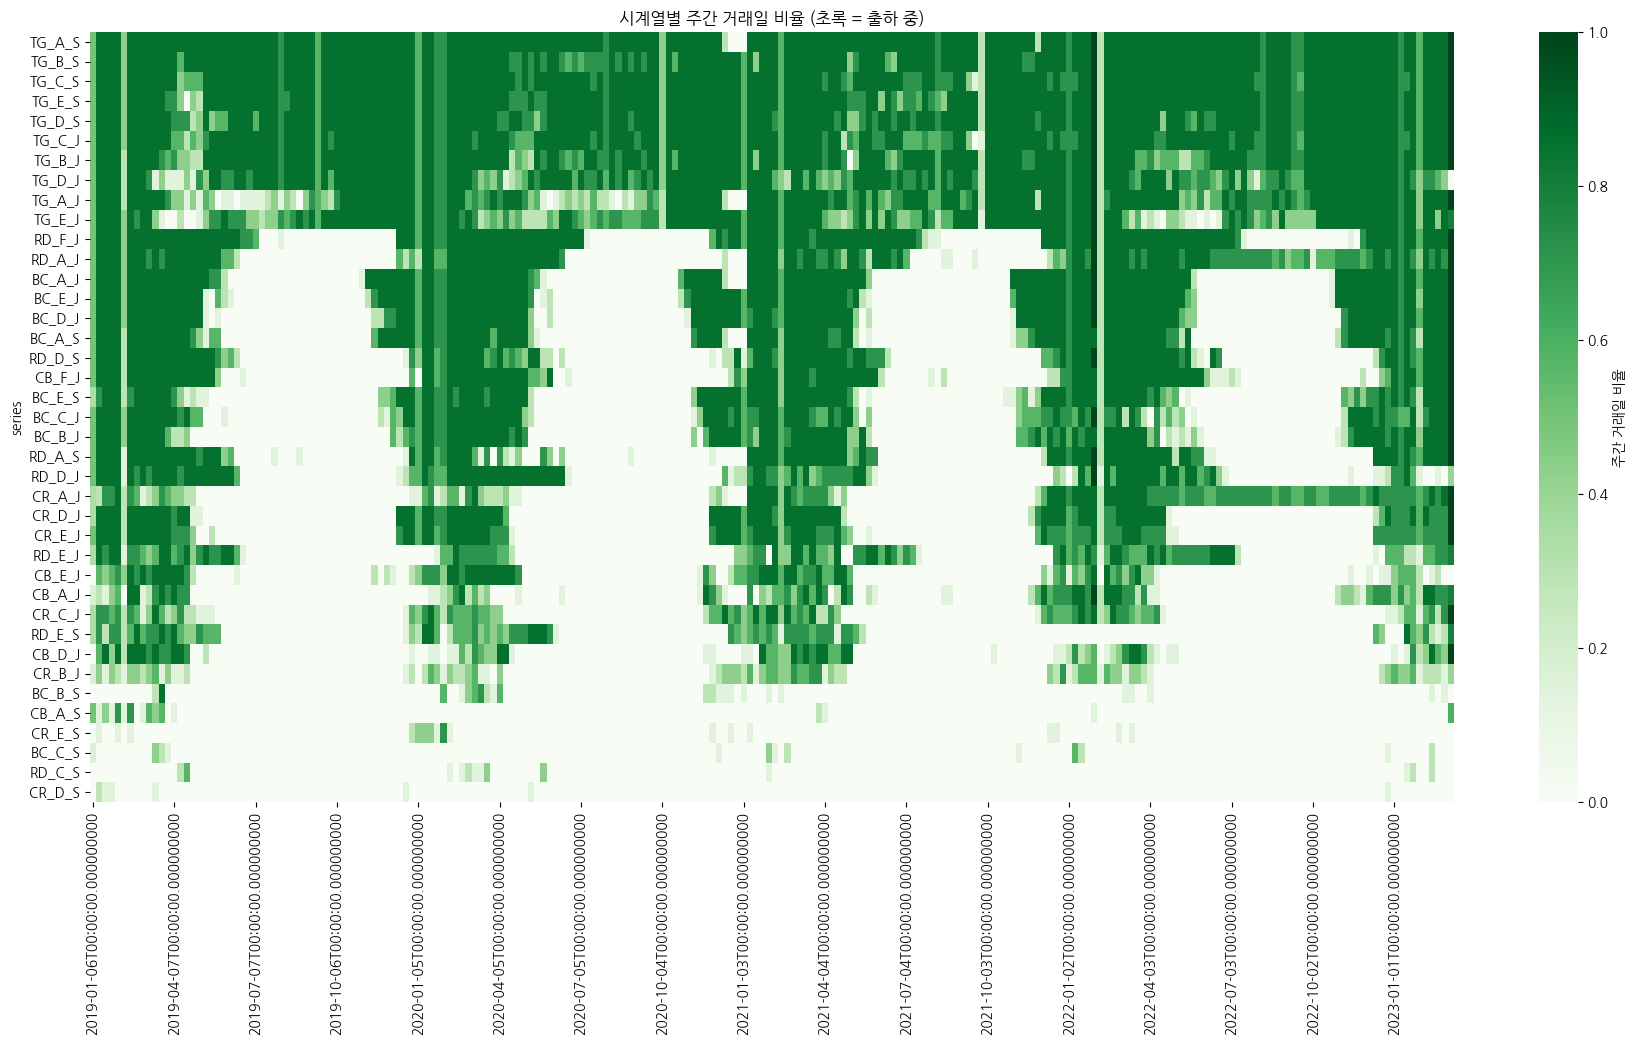

,2019년,2020년,2021년,2022년,2023년,평균
series,,,,,,
CR_D_S,0,0,0,0,0,0.000
BC_C_S,0,0,0,1,0,0.200
CR_E_S,0,1,0,0,0,0.200
RD_C_S,1,0,0,0,0,0.200
CB_A_S,4,0,0,0,1,1.000
BC_B_S,1,4,0,0,0,1.200
CR_B_J,1,2,9,4,2,4.000
CB_D_J,13,5,13,6,4,9.200
CB_A_J,9,5,16,15,7,11.200


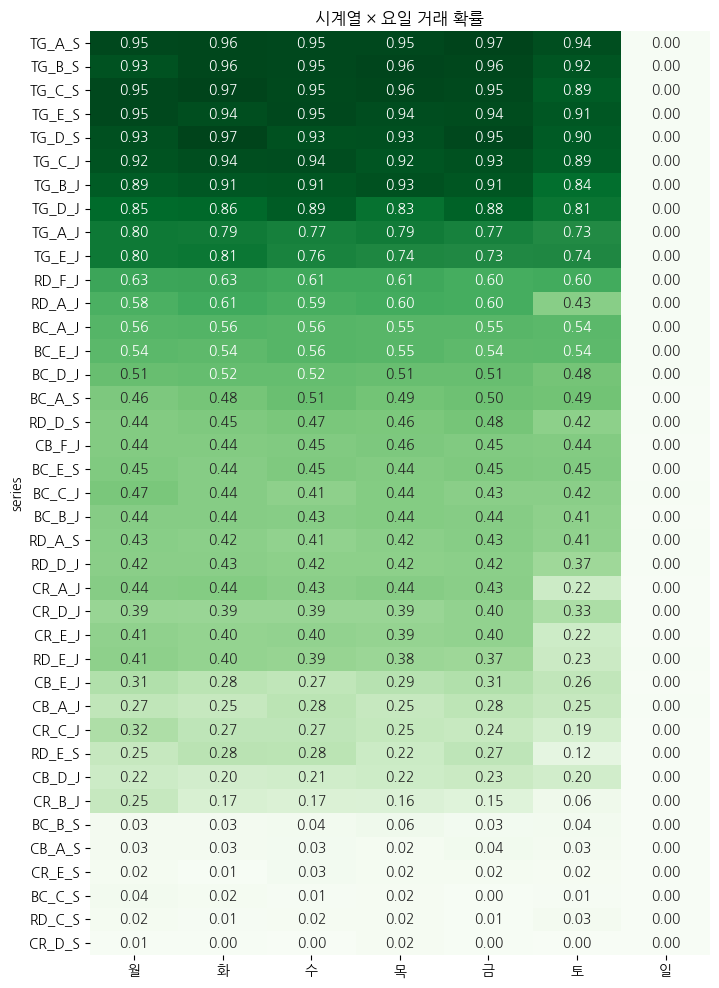

In [ ]:
train = pd.read_csv(TRAIN_PATH).rename(columns={'supply(kg)': 'supply', 'price(원/kg)': 'price'})
test = pd.read_csv(TEST_PATH)
trade = pd.read_csv(TRADE_PATH)
sub = pd.read_csv(SUB_PATH)
for d in (train, test):
    d['timestamp'] = pd.to_datetime(d['timestamp'])
    d['series'] = d['item'] + '_' + d['corporation'] + '_' + d['location']

dates = pd.date_range(train.timestamp.min(), test.timestamp.max())
SERIES = sorted(train.series.unique())
P = train.pivot(index='timestamp', columns='series', values='price').reindex(dates)[SERIES]   # 가격 (test 구간 NaN)
S = train.pivot(index='timestamp', columns='series', values='supply').reindex(dates)[SERIES]  # 공급량
T = (P > 0).astype(float).where(P.notna())                                                     # 거래 여부
item_of = pd.Series({s: s[:2] for s in SERIES})

print('가격 행렬:', P.shape, '| 결측(=test 구간) 행 수:', P.isna().all(axis=1).sum())
print('거래일 비율: {:.1%}'.format(T.stack().mean()))
display(P.tail(3).iloc[:, :8])

wk_rate = T.loc[:'2023-03-03'].resample('W').mean()
order = wk_rate.mean().sort_values(ascending=False).index
plt.figure(figsize=(22, 10))
sns.heatmap(wk_rate[order].T, cmap='Greens', cbar_kws={'label': '주간 거래일 비율'}, xticklabels=13)
plt.title('시계열별 주간 거래일 비율 (초록 = 출하 중)'); plt.show()


#시즌 길이: 연도별로 거래일 비율이 50%를 넘는 주(week)의 수
season = (wk_rate > 0.5).groupby(wk_rate.index.year).sum().T
season.columns = [f'{c}년' for c in season.columns]
season['평균'] = season.iloc[:, :4].mean(axis=1)
display(season.sort_values('평균').round(1))


#일요일을 뺀 요일별 거래 확률 — 시계열마다 쉬는 요일 패턴이 다른가
dow_rate = T.loc[:'2023-03-03'].groupby(T.loc[:'2023-03-03'].index.dayofweek).mean().T
dow_rate.columns = ['월', '화', '수', '목', '금', '토', '일']
plt.figure(figsize=(8, 12))
sns.heatmap(dow_rate.loc[order], annot=True, fmt='.2f', cmap='Greens', cbar=False)
plt.title('시계열 × 요일 거래 확률'); plt.show()

#3. EDA 분석

### EDA  1 - 거래 시즌 패턴으로 시계열 군집화

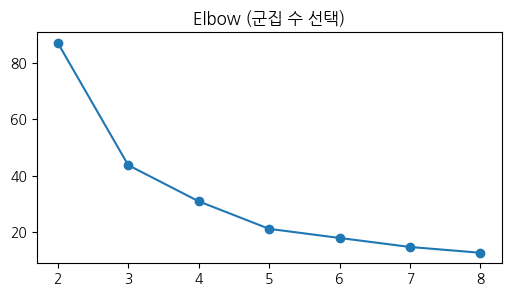

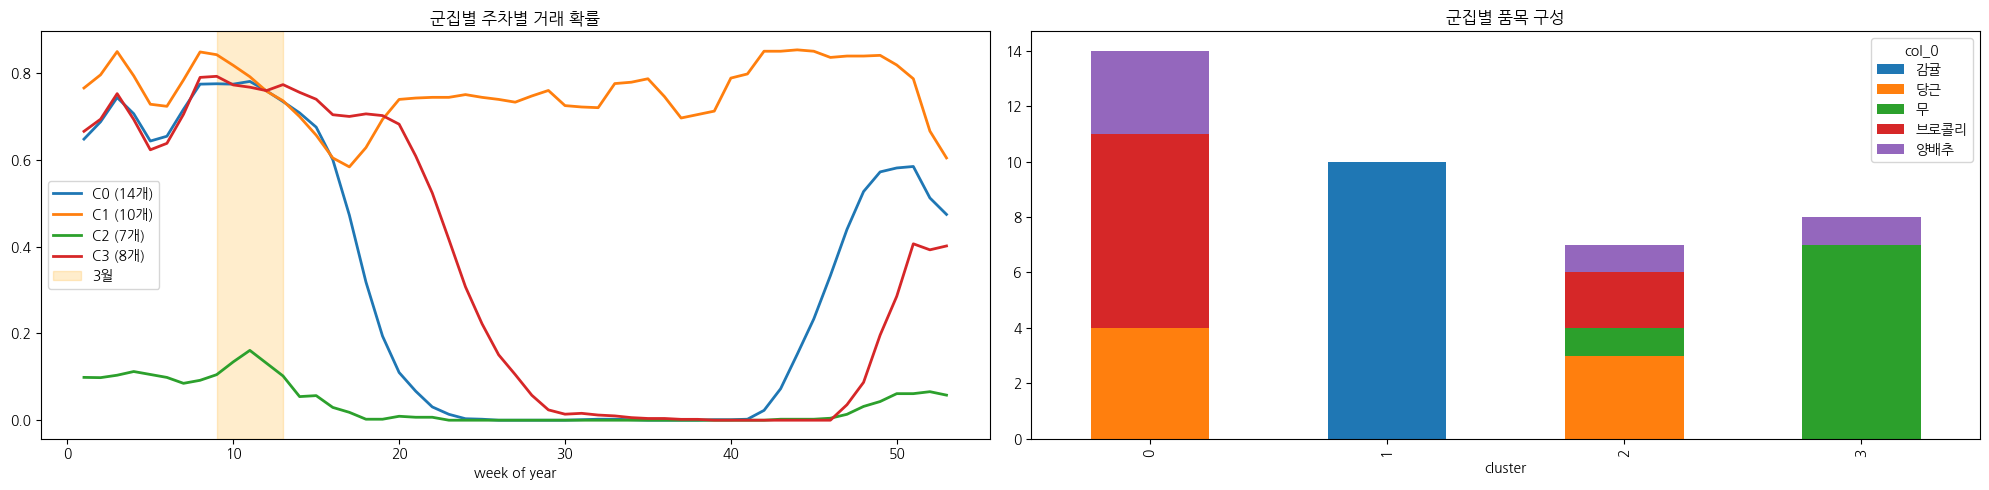

cluster
0    [BC_A_J, BC_A_S, BC_B_J, BC_C_J, BC_D_J, BC_E_...
1    [TG_A_J, TG_A_S, TG_B_J, TG_B_S, TG_C_J, TG_C_...
2    [BC_B_S, BC_C_S, CB_A_S, CR_B_J, CR_D_S, CR_E_...
3    [CB_F_J, RD_A_J, RD_A_S, RD_D_J, RD_D_S, RD_E_...


In [ ]:
from sklearn.cluster import KMeans

hist = T.loc[:'2022-02-28']
prof = hist.groupby(hist.index.isocalendar().week.values).mean().T   # 39 × 53
prof = prof.T.rolling(3, min_periods=1, center=True).mean().T   # 주차 방향으로 살짝 평활
inertia = [KMeans(k, n_init=20, random_state=0).fit(prof).inertia_ for k in range(2, 9)]
plt.figure(figsize=(6, 3)); plt.plot(range(2, 9), inertia, 'o-'); plt.title('Elbow (군집 수 선택)'); plt.show()

K = 4
km = KMeans(K, n_init=20, random_state=0).fit(prof)
cluster = pd.Series(km.labels_, index=SERIES, name='cluster')

fig, ax = plt.subplots(1, 2, figsize=(20, 5))
for k in range(K):
    ax[0].plot(prof.columns, prof[cluster == k].mean(), lw=2, label=f'C{k} ({(cluster == k).sum()}개)')
ax[0].axvspan(9, 13, color='orange', alpha=.2, label='3월'); ax[0].legend(); ax[0].set_title('군집별 주차별 거래 확률')
ax[0].set_xlabel('week of year')
pd.crosstab(cluster, item_of.map(ITEM_KR)).plot.bar(stacked=True, ax=ax[1], title='군집별 품목 구성')
plt.tight_layout(); plt.show()
print(cluster.groupby(cluster).apply(lambda x: list(x.index)).to_string())

### EDA 2 - 이상치 Hampel 필터

이상치 개수(시계열 상위 10):


,n
series,
TG_A_J,74
TG_B_J,69
TG_C_J,68
TG_D_S,67
TG_D_J,61
TG_E_J,59
TG_E_S,55
TG_B_S,54
CR_A_J,48


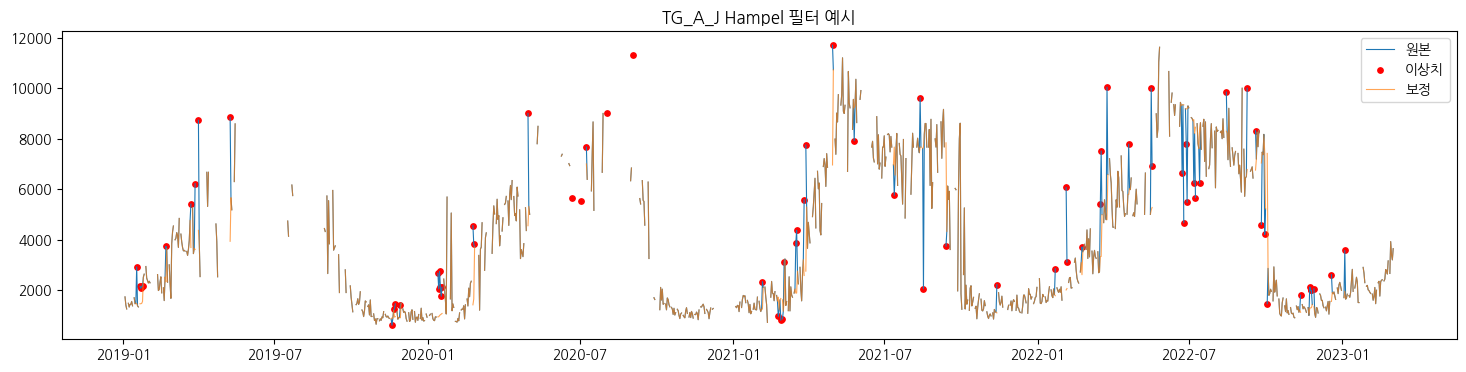

In [ ]:
Pnz = P.where(P > 0)
med = Pnz.rolling(15, min_periods=3).median()
mad = (Pnz - med).abs().rolling(15, min_periods=3).median()
is_out = (Pnz - med).abs() > 3 * 1.4826 * mad.replace(0, np.nan)
Pclean = Pnz.mask(is_out, med)

print('이상치 개수(시계열 상위 10):'); display(is_out.sum().sort_values(ascending=False).head(10).to_frame('n'))
s_ex = is_out.sum().idxmax()
fig, ax = plt.subplots(figsize=(18, 4))
ax.plot(Pnz[s_ex], lw=.8, label='원본'); ax.scatter(Pnz.index[is_out[s_ex]], Pnz[s_ex][is_out[s_ex]], c='r', s=15, label='이상치')
ax.plot(Pclean[s_ex], lw=.8, alpha=.7, label='보정'); ax.set_title(f'{s_ex} Hampel 필터 예시'); ax.legend(); plt.show()

### EDA 3  - 가격을 시계열 수준으로 나눠 보기 (정규화)

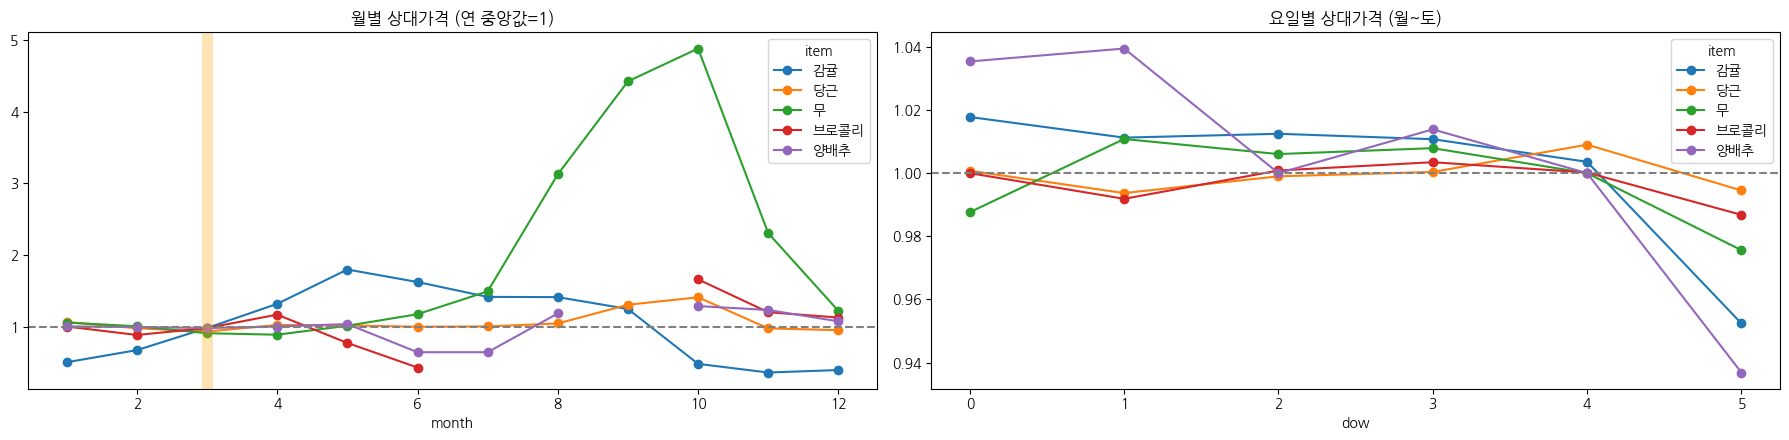

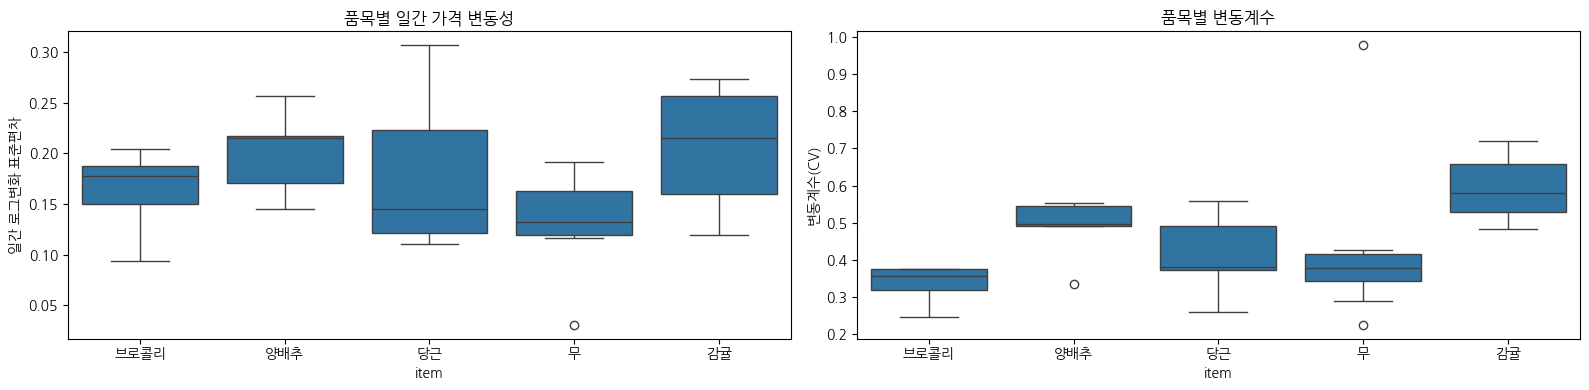

In [ ]:
yr_med = Pclean.groupby(Pclean.index.year).transform('median')
R = Pclean / yr_med   # 상대가격
rel = R.loc[:'2023-03-03'].stack().rename('rel').reset_index()
rel.columns = ['timestamp', 'series', 'rel']
rel['item'] = rel.series.str[:2].map(ITEM_KR)
rel['month'] = rel.timestamp.dt.month
rel['dow'] = rel.timestamp.dt.dayofweek

fig, ax = plt.subplots(1, 2, figsize=(18, 4.5))
rel.groupby(['month', 'item']).rel.median().unstack().plot(ax=ax[0], marker='o', title='월별 상대가격 (연 중앙값=1)')
ax[0].axhline(1, c='gray', ls='--'); ax[0].axvline(3, c='orange', lw=8, alpha=.3)
rel[rel.dow < 6].groupby(['dow', 'item']).rel.median().unstack().plot(ax=ax[1], marker='o', title='요일별 상대가격 (월~토)')
ax[1].axhline(1, c='gray', ls='--')
plt.tight_layout(); plt.show()

# %%
# 시계열별 변동성: 일간 변화율 분포 & 변동계수
chg = np.log(Pclean).diff()
vol = pd.DataFrame({'일간 로그변화 표준편차': chg.std(), '변동계수(CV)': Pnz.std() / Pnz.mean(), 'item': item_of.map(ITEM_KR)})
fig, ax = plt.subplots(1, 2, figsize=(16, 4))
sns.boxplot(data=vol, x='item', y='일간 로그변화 표준편차', ax=ax[0]); ax[0].set_title('품목별 일간 가격 변동성')
sns.boxplot(data=vol, x='item', y='변동계수(CV)', ax=ax[1]); ax[1].set_title('품목별 변동계수')
plt.tight_layout(); plt.show()

### EDA 4 - 시계열 분해 (STL) 추세와 계절성의 비중

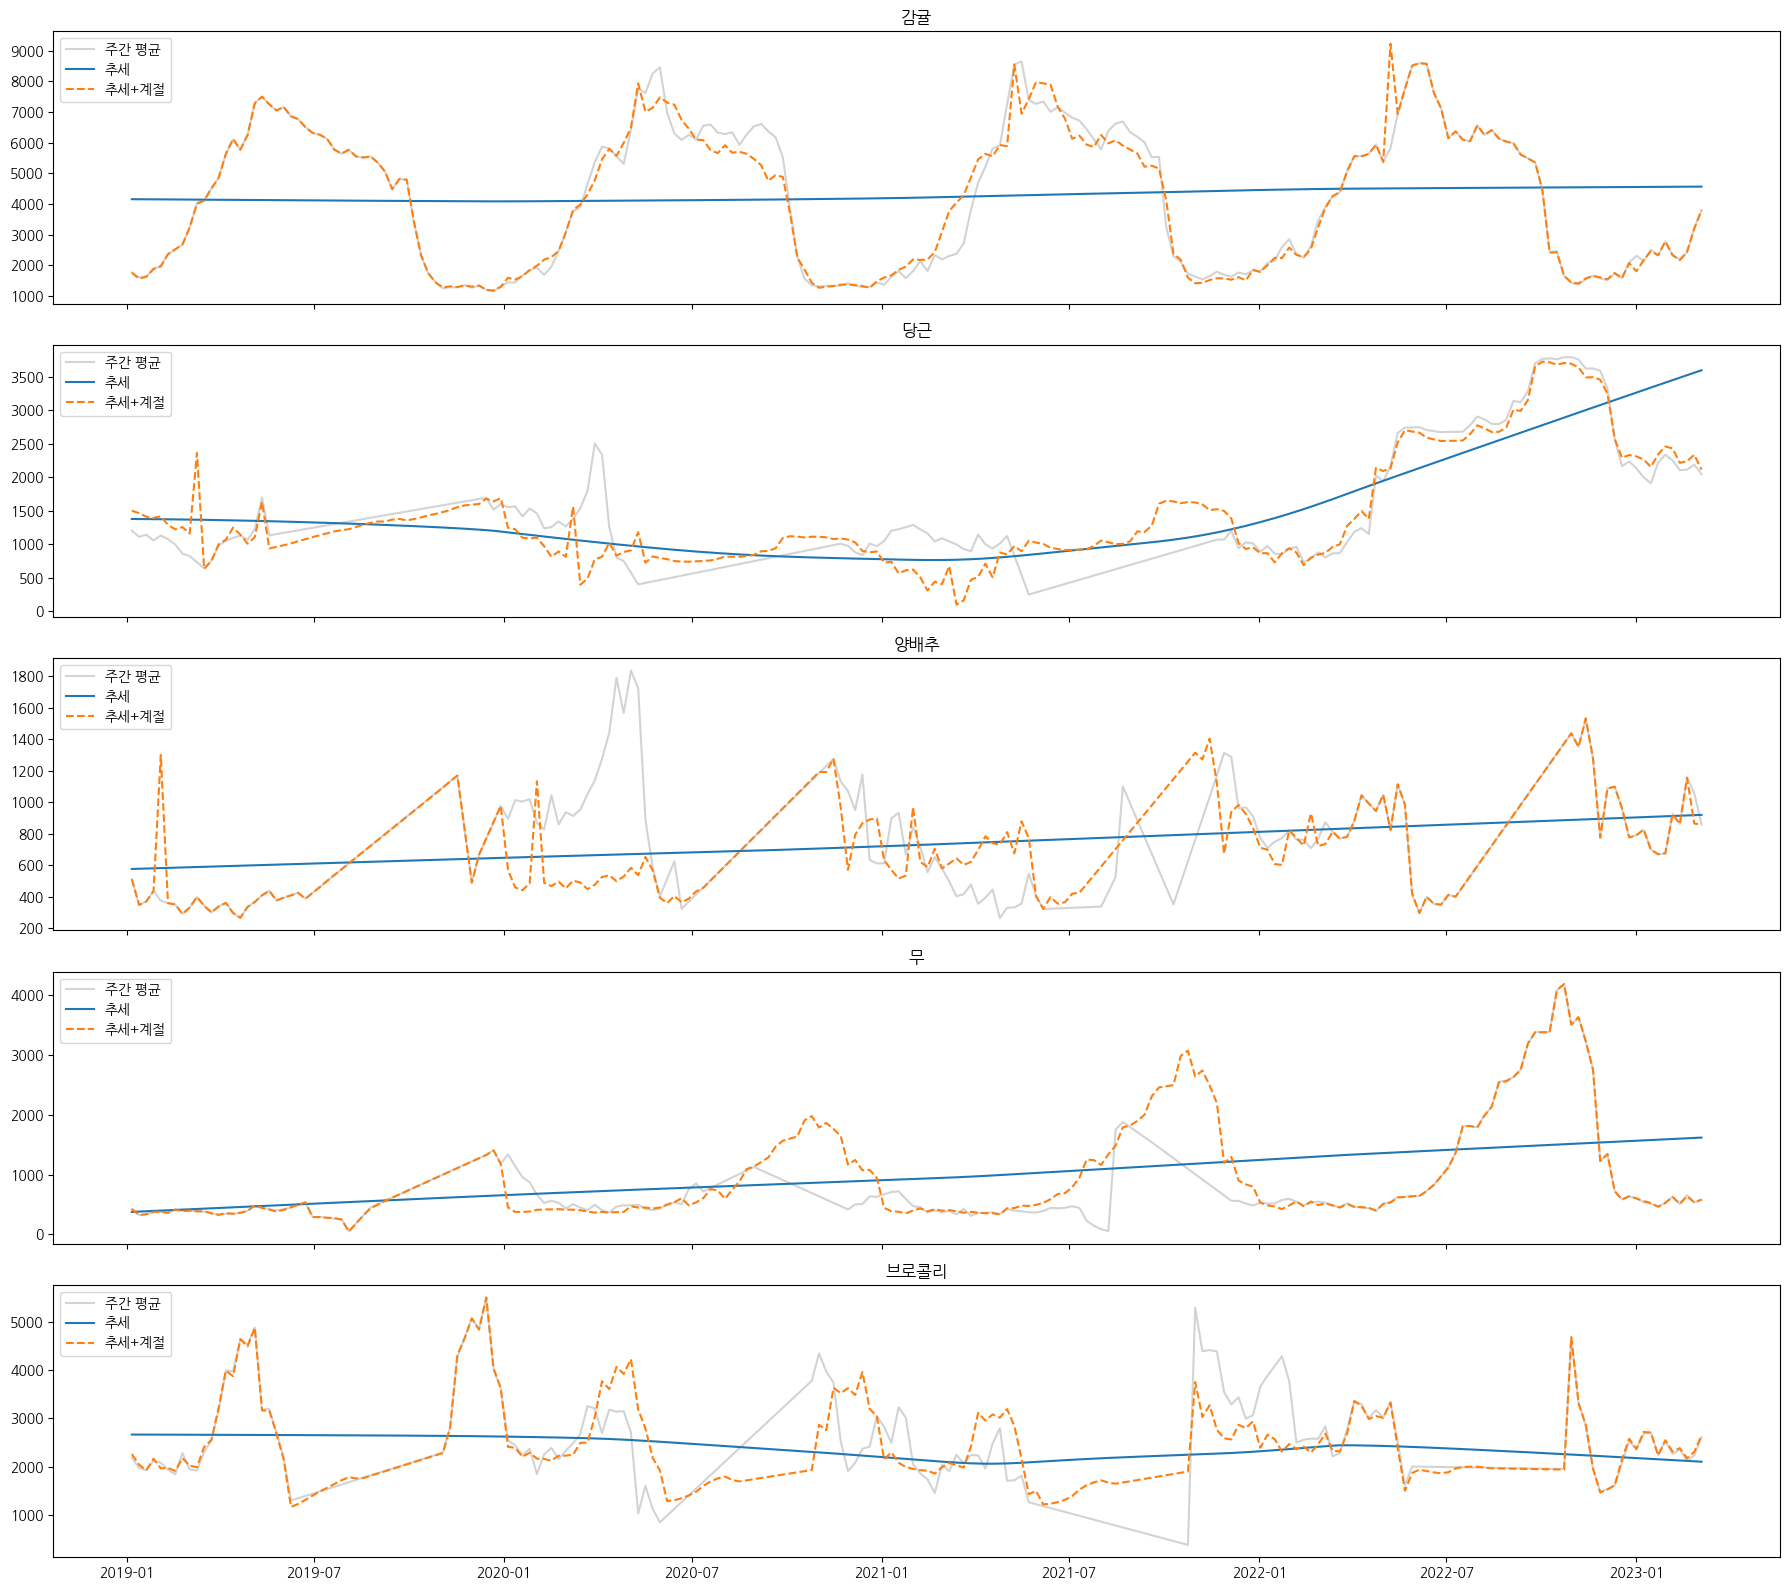

,추세 강도,계절성 강도
감귤,0.090,0.960
당근,0.790,0.430
양배추,0.010,0.220
무,0.330,0.580
브로콜리,0.120,0.550


In [ ]:
from statsmodels.tsa.seasonal import STL

fig, axes = plt.subplots(5, 1, figsize=(18, 16), sharex=True)
strength = {}
for ax, it in zip(axes, ITEMS):
    w = Pclean.loc[:'2023-03-03', item_of[item_of == it].index].mean(axis=1).resample('W').mean().interpolate().bfill()
    r = STL(w, period=52, robust=True).fit()
    strength[ITEM_KR[it]] = {'추세 강도': max(0, 1 - r.resid.var() / (r.trend + r.resid).var()),
                             '계절성 강도': max(0, 1 - r.resid.var() / (r.seasonal + r.resid).var())}
    ax.plot(w, c='lightgray', label='주간 평균'); ax.plot(r.trend, label='추세'); ax.plot(r.trend + r.seasonal, ls='--', label='추세+계절')
    ax.set_title(ITEM_KR[it]); ax.legend(loc='upper left')
plt.tight_layout(); plt.show()
display(pd.DataFrame(strength).T.round(2))

### EDA 5 - 공급 탄력성 (공급이 1% 늘면 가격은 몇 % 변하나)

In [ ]:
lp, ls_ = np.log(Pnz), np.log(S.where(S > 0))
rows = []
for it in ITEMS:
    cols = item_of[item_of == it].index
    for lag in [0, 7, 28]:
        x = (ls_[cols].shift(lag) - ls_[cols].mean()).stack()
        y = (lp[cols] - lp[cols].mean()).stack()
        xy = pd.concat([x, y], axis=1).dropna()
        rows.append([ITEM_KR[it], lag, np.polyfit(xy[0], xy[1], 1)[0], xy.corr().iloc[0, 1]])
elas = pd.DataFrame(rows, columns=['품목', '공급 lag(일)', '탄력성', '상관'])
display(elas.pivot(index='품목', columns='공급 lag(일)', values='탄력성').round(3))
print('→ 같은 날 공급 탄력성은 음수이지만, 28일 전 공급량의 설명력은 크게 줄어든다. 공급량은 보조 피처로만 사용.')

공급 lag(일),0,7,28
품목,,,
감귤,-0.333,-0.320,-0.258
당근,-0.174,-0.176,-0.182
무,-0.196,-0.193,-0.189
브로콜리,-0.085,-0.079,-0.028
양배추,-0.136,-0.121,-0.122


→ 같은 날 공급 탄력성은 음수이지만, 28일 전 공급량의 설명력은 크게 줄어든다. 공급량은 보조 피처로만 사용.


### EDA 6 - 예측 지평에 따른 불확실성

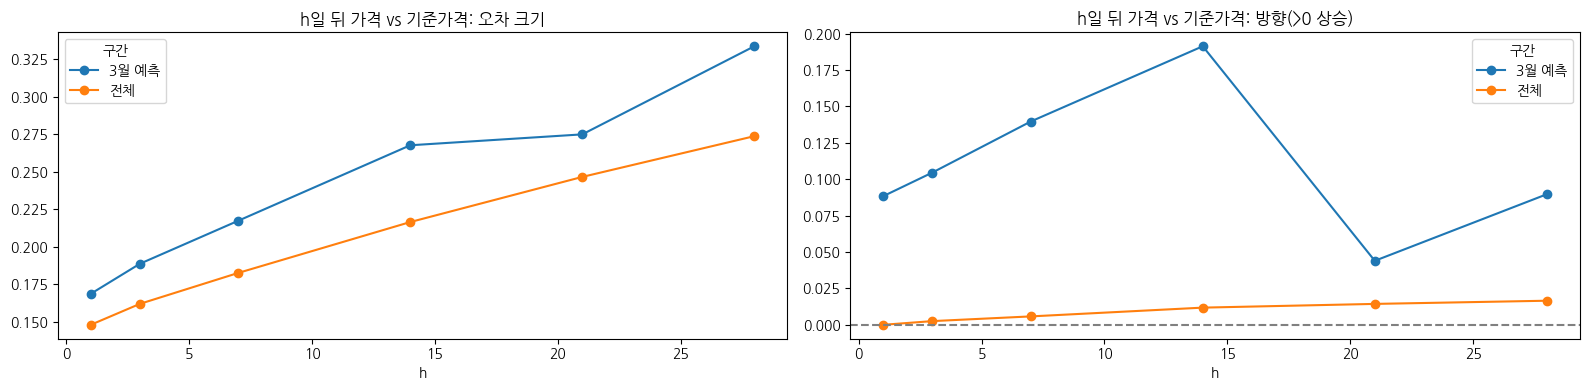

→ h가 커질수록 기준가격만으로는 오차가 커지고, 3월에는 가격이 기준가격보다 오르는 경향이 있다 → 변화율(Ratio)을 따로 학습


In [ ]:
level = Pclean.rolling(28, min_periods=3).median()
level = level.fillna(Pclean.rolling(91, min_periods=3).median()).fillna(Pclean.rolling(364, min_periods=1).median())
level = level.fillna(Pclean.expanding().median())                         # 1년 넘게 거래 없음 → 전체 과거 중앙값
level = level.fillna(level.T.groupby(item_of).transform('median').T)        # 거래 이력 자체가 없음 → 같은 품목 중앙값
level = level.fillna(level.T.groupby(item_of).transform('median').T.bfill())
rows = []
for h in [1, 3, 7, 14, 21, 28]:
    lr = np.log(Pnz.shift(-h) / level).loc[:'2023-02-01']
    for m in [None, 3]:
        v = lr if m is None else lr[lr.index.month == (m - 1 if h > 14 else m)]
        v = v.stack()
        rows.append([h, '전체' if m is None else '3월 예측', v.abs().median(), v.median()])
hz = pd.DataFrame(rows, columns=['h', '구간', '|log ratio| 중앙값', 'log ratio 중앙값'])
fig, ax = plt.subplots(1, 2, figsize=(16, 4))
hz.pivot(index='h', columns='구간', values='|log ratio| 중앙값').plot(marker='o', ax=ax[0], title='h일 뒤 가격 vs 기준가격: 오차 크기')
hz.pivot(index='h', columns='구간', values='log ratio 중앙값').plot(marker='o', ax=ax[1], title='h일 뒤 가격 vs 기준가격: 방향(>0 상승)')
ax[1].axhline(0, c='gray', ls='--'); plt.tight_layout(); plt.show()
print('→ h가 커질수록 기준가격만으로는 오차가 커지고, 3월에는 가격이 기준가격보다 오르는 경향이 있다 → 변화율(Ratio)을 따로 학습')

### EDA 7 — 전년 대비 변화율 관점

In [ ]:
trade.columns = ['ym', 'trade_item', 'exp_w', 'exp_amt', 'imp_w', 'imp_amt', 'balance']
TRADE_MAP = {'감귤': 'TG', '당근': 'CR', '양배추': 'CB', '꽃양배추와 브로콜리(broccoli)': 'BC'}
tt = trade[trade.trade_item.isin(TRADE_MAP)].assign(item=lambda d: d.trade_item.map(TRADE_MAP))
tt['ym'] = pd.to_datetime(tt.ym)
tw = tt.pivot(index='ym', columns='item', values='imp_w').add(tt.pivot(index='ym', columns='item', values='exp_w'), fill_value=0)
pm = pd.DataFrame({it: Pnz[item_of[item_of == it].index].mean(axis=1).resample('MS').mean() for it in ITEMS})
yoy = pd.DataFrame({ITEM_KR[it]: [np.log(pm[it]).diff(12).corr(np.log1p(tw[it]).diff(12).shift(k)) for k in [0, 1, 2]]
                    for it in tw.columns}, index=['동월', '1개월 선행', '2개월 선행']).T
display(yoy.round(2))
print('→ 상관이 품목마다 부호와 크기가 일정하지 않음 → 모델 피처에서 제외 (과적합 방지)')

,동월,1개월 선행,2개월 선행
브로콜리,0.210,-0.150,-0.250
양배추,0.700,0.540,0.400
당근,0.320,0.180,0.390
감귤,-0.280,-0.020,0.030


→ 상관이 품목마다 부호와 크기가 일정하지 않음 → 모델 피처에서 제외 (과적합 방지)


# 전처리

In [ ]:
nz_mean7 = Pclean.rolling(7, min_periods=1).mean()
nz_mean28 = Pclean.rolling(28, min_periods=1).mean()
nz_std28 = Pclean.rolling(28, min_periods=3).std()
last_price = Pclean.ffill()
trade_rate28 = T.rolling(28, min_periods=1).mean()
trade_rate7 = T.rolling(7, min_periods=1).mean()
# 마지막 거래 후 경과일
idx = np.arange(len(dates))[:, None].repeat(len(SERIES), 1)
last_tr = pd.DataFrame(np.where(T.values == 1, idx, np.nan), index=dates, columns=SERIES).ffill()
days_since = idx - last_tr.values
sup_mean28 = S.where(S > 0).rolling(28, min_periods=1).mean()
# 작년 같은 날 기준 ±3일 거래가격 / 거래확률 (centered)
c_price7 = Pclean.rolling(7, center=True, min_periods=1).mean()
c_trade7 = T.rolling(7, center=True, min_periods=1).mean()
# 품목 공통: 품목 시계열들의 (최근7일 / 기준가격) 평균
mom = (nz_mean7 / level)
item_mom = mom.T.groupby(item_of).transform('mean').T

state = {k: v.values for k, v in dict(level=level, nz_mean7=nz_mean7, nz_mean28=nz_mean28, nz_std28=nz_std28,
                                     last_price=last_price, trade_rate28=trade_rate28, trade_rate7=trade_rate7,
                                     sup_mean28=sup_mean28, c_price7=c_price7, c_trade7=c_trade7,
                                     item_mom=item_mom).items()}
state['days_since'] = days_since
Tv, Pv = T.values, P.values
print({k: v.shape for k, v in state.items()})

{'level': (1551, 39), 'nz_mean7': (1551, 39), 'nz_mean28': (1551, 39), 'nz_std28': (1551, 39), 'last_price': (1551, 39), 'trade_rate28': (1551, 39), 'trade_rate7': (1551, 39), 'sup_mean28': (1551, 39), 'c_price7': (1551, 39), 'c_trade7': (1551, 39), 'item_mom': (1551, 39), 'days_since': (1551, 39)}


학습 데이터: (307944, 31) | 예측 시점 수: 282


,origin,target,series,h,item,corp,loc,cluster,s_code,t_dow,t_month,t_doy,o_dow,level_log,mom7,mom28,cv28,last_ratio,trade_rate7,trade_rate28,days_since,item_mom,sup_log,dow_trade4,ly_ratio,ly_trade,ly2_ratio,y,trade,log_ratio,lev
252020,2022-07-13,2022-08-03,TG_A_S,21,4,0,1,1,30,2,8,215,2,8.717,0.943,1.008,0.119,0.890,0.857,0.857,0.000,0.955,8.349,1.000,0.913,0.714,1.060,"6,251.000",1.000,0.023,"6,108.000"
112952,2021-02-20,2021-02-21,CR_D_J,1,2,3,0,0,17,6,2,52,5,7.150,0.855,0.963,0.124,0.495,0.857,0.714,0.000,0.848,10.945,0.000,0.954,0.857,0.875,0.000,0.000,NaN,"1,274.000"
263889,2022-08-26,2022-09-13,RD_D_S,18,3,3,1,3,25,1,9,256,4,6.735,NaN,NaN,NaN,0.892,0.000,0.000,70.000,1.172,NaN,0.000,NaN,0.000,NaN,0.000,0.000,NaN,841.000
100743,2021-01-07,2021-02-04,CB_A_J,28,1,0,0,0,9,3,2,35,3,6.655,1.085,1.085,0.230,1.064,0.571,0.143,0.000,1.127,9.028,0.250,2.015,0.429,NaN,0.000,0.000,NaN,776.500
136487,2021-05-15,2021-05-31,TG_E_S,16,4,4,1,1,38,0,5,151,5,8.835,1.369,1.008,0.442,1.146,0.714,0.750,0.000,1.134,6.562,1.000,0.933,0.857,0.957,"6,032.000",1.000,-0.130,"6,871.000"


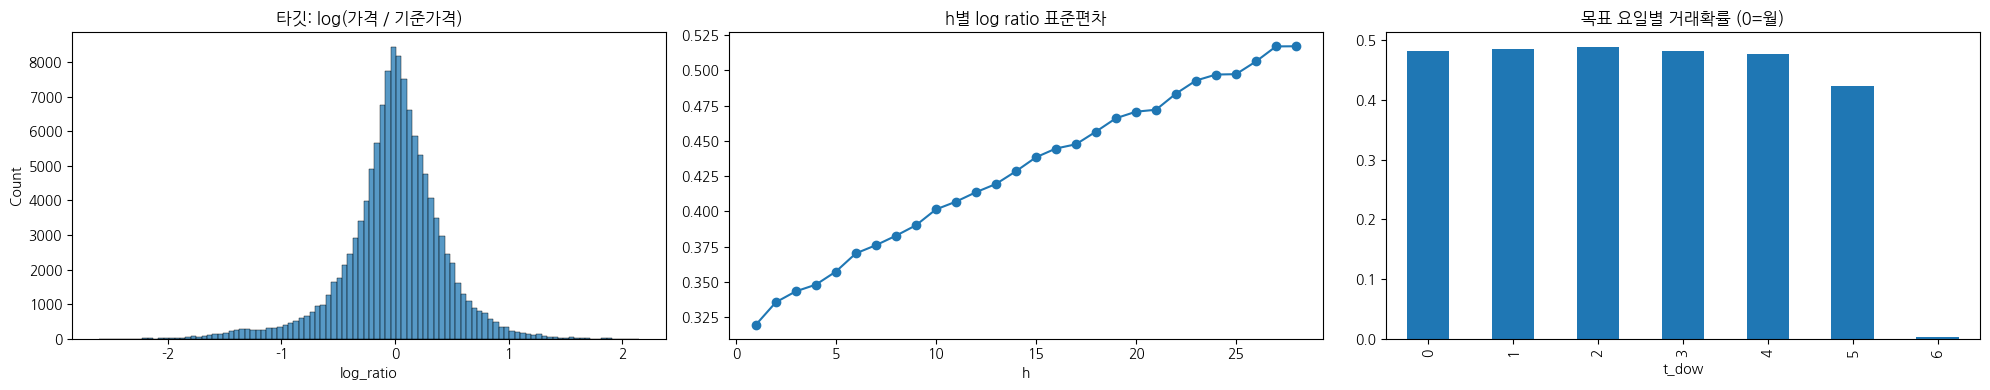

In [ ]:
s_code = np.arange(len(SERIES))
item_code = pd.Series(item_of.values).astype('category').cat.codes.values
clus = cluster.reindex(SERIES).values
corp_code = pd.Series([s[3] for s in SERIES]).astype('category').cat.codes.values
loc_code = (pd.Series([s[5] for s in SERIES]) == 'S').astype(int).values
date_pos = {d: i for i, d in enumerate(dates)}

def make_rows(origin_idx):
    o = np.repeat(origin_idx, len(SERIES) * H)
    s = np.tile(np.repeat(s_code, H), len(origin_idx))
    h = np.tile(np.arange(1, H + 1), len(origin_idx) * len(SERIES))
    t = o + h
    tdate = dates[t]
    lev = state['level'][o, s]
    f = pd.DataFrame({
        'origin': dates[o], 'target': tdate, 'series': np.array(SERIES)[s], 'h': h,
        'item': item_code[s], 'corp': corp_code[s], 'loc': loc_code[s], 'cluster': clus[s], 's_code': s,
        't_dow': tdate.dayofweek, 't_month': tdate.month, 't_doy': tdate.dayofyear, 'o_dow': dates[o].dayofweek,
        'level_log': np.log(lev),
        'mom7': state['nz_mean7'][o, s] / lev, 'mom28': state['nz_mean28'][o, s] / lev,
        'cv28': state['nz_std28'][o, s] / lev, 'last_ratio': state['last_price'][o, s] / lev,
        'trade_rate7': state['trade_rate7'][o, s], 'trade_rate28': state['trade_rate28'][o, s],
        'days_since': state['days_since'][o, s], 'item_mom': state['item_mom'][o, s],
        'sup_log': np.log(state['sup_mean28'][o, s]),
    })
    # 목표 요일과 같은 요일의, 예측 시점 이전 최근 4주 거래 여부 평균
    m0 = np.ceil(h / 7).astype(int)
    f['dow_trade4'] = np.nanmean(np.stack([Tv[t - 7 * (m0 + k), s] for k in range(4)]), axis=0)
    # 작년: 목표일(t-364) 주변 가격 / 작년 예측시점 기준가격 → 작년의 같은 h 변화율
    ly_lev = state['level'][o - 364, s]
    f['ly_ratio'] = state['c_price7'][t - 364, s] / ly_lev
    f['ly_trade'] = state['c_trade7'][t - 364, s]
    f['ly2_ratio'] = np.where(o - 728 >= 0, state['c_price7'][np.maximum(t - 728, 0), s] / state['level'][np.maximum(o - 728, 0), s], np.nan)
    # 타깃
    y = Pv[t, s]
    f['y'] = y
    f['trade'] = (y > 0).astype(float)
    f['log_ratio'] = np.where(y > 0, np.log(np.where(y > 0, y, 1) / lev), np.nan)
    f['lev'] = lev
    return f

FEATS = ['h', 'item', 'corp', 'loc', 'cluster', 's_code', 't_dow', 't_month', 't_doy', 'o_dow', 'level_log',
         'mom7', 'mom28', 'cv28', 'last_ratio', 'trade_rate7', 'trade_rate28', 'days_since', 'item_mom', 'sup_log',
         'dow_trade4', 'ly_ratio', 'ly_trade', 'ly2_ratio']

first_origin = date_pos[pd.Timestamp('2020-01-05')]           # 작년 피처 확보 이후
last_known = date_pos[pd.Timestamp('2023-03-03')]
all_origins = np.arange(first_origin, last_known - H + 1, 4)
DS = make_rows(all_origins)
print('학습 데이터:', DS.shape, '| 예측 시점 수:', len(all_origins))
display(DS.sample(5, random_state=0))
fig, ax = plt.subplots(1, 3, figsize=(20, 4))
sns.histplot(DS.log_ratio.dropna(), bins=100, ax=ax[0]); ax[0].set_title('타깃: log(가격 / 기준가격)')
DS.groupby('h').log_ratio.std().plot(ax=ax[1], marker='o', title='h별 log ratio 표준편차')
DS.groupby('t_dow').trade.mean().plot.bar(ax=ax[2], title='목표 요일별 거래확률 (0=월)')
plt.tight_layout(); plt.show()

## 📌 요약 (EDA + 전처리)

**핵심 아이디어**: 가격을 그대로 예측하지 않고 세 부분으로 나눠서 예측한다.
> **가격 = 거래 여부 × 기준가격 × 변화율**
> - 기준가격: 예측 시점 직전 28일 거래가격의 중앙값
> - 변화율: 기준가격 대비 h일 뒤 가격이 몇 배인지

**EDA에서 알게 된 것**
1. 전체의 약 60%가 가격 0 = 거래가 없는 날 (일요일은 100% 0). 시계열마다 출하 시즌과 쉬는 요일이 다르다.
2. 출하 시즌 패턴으로 묶으면 39개 시계열이 4개 유형으로 나뉜다. 3월에 거의 거래가 없는 시계열 그룹도 따로 있다.
3. 감귤은 계절성이 매우 강하고(0.96), 당근은 추세가 강하다(0.79).
4. 공급이 늘면 가격이 내려간다. 감귤이 가장 민감하다(공급 +1% → 가격 약 -0.33%).
5. 예측 거리(h)가 멀수록 기준가격만으로는 오차가 커지고, 3월에는 가격이 오르는 경향이 있다.
6. 수출입 데이터는 품목마다 상관의 방향이 들쭉날쭉해서 피처에서 뺐다.

**전처리**
- 튀는 가격은 Hampel 필터로 보정 (피처 계산에만 쓰고, 정답 값은 그대로)
- 학습 데이터를 **(예측 시점 × 시계열 × 1~28일 뒤)** 단위로 새로 만듦 → 30만 7944행, 피처 24개
- 주요 피처: 기준가격, 최근 추세, 요일별 최근 거래확률, 작년 같은 시기 변화율, 출하 군집
- 모든 피처는 예측 시점까지의 데이터만 사용 (미래 정보 누수 없음)

**모델링 계획**
- 거래 여부 분류 모델 + 변화율 회귀 모델
- 최종 예측 = 거래 확률 × (기준가격 × 변화율)
- 저장 파일: `train_levelratio.csv`, `test_levelratio.csv`, `features_levelratio.csv`